# Reelpath · A recommendation with a reason
Real Neo4j, historical MovieLens ratings and verifiable graph paths. Run `make download seed analytics` and start the stack first.

In [1]:
from pathlib import Path
import json
import httpx
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display, SVG, Image
from app.config import ROOT, get_settings
BASE = 'http://127.0.0.1:18080'
client = httpx.Client(base_url=BASE, timeout=70)
status = client.get('/api/system/status').json()
{k: status[k] for k in ['users','movies','ratings','tag_applications','as_of']}

{'users': 610,
 'movies': 9742,
 'ratings': 100836,
 'tag_applications': 3683,
 'as_of': 1537799250}

## 1 · A deliberately modeled graph
Genres are shared nodes; ratings are edges; tag applications preserve event provenance. Analytical runs are separate from observed source facts.

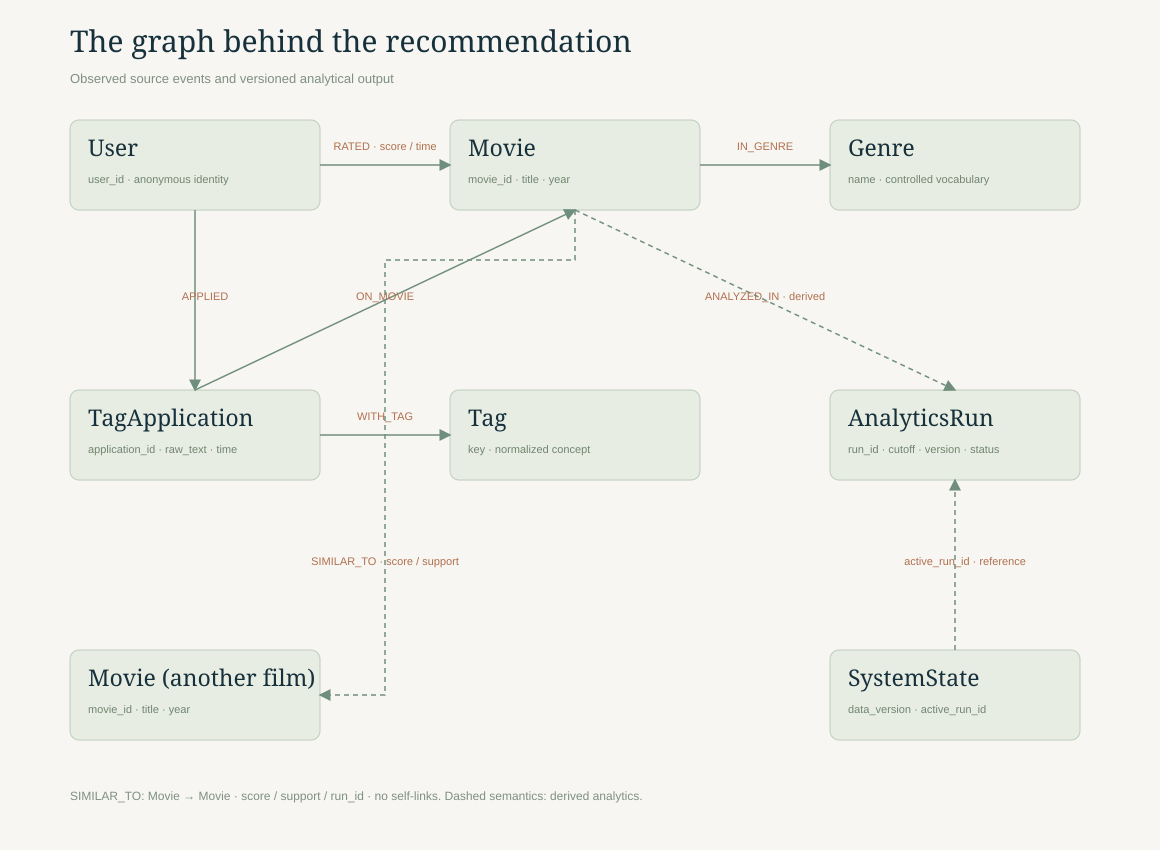

In [2]:
display(SVG(filename=str(ROOT/'docs/diagrams/schema.svg')))

### Tag event provenance
A tag is a subjective user annotation, not a verified plot claim. The event node preserves who tagged which movie and when.

In [3]:
from app.database import GraphStore
store = GraphStore(get_settings())
try:
    tag_events = store.read('''MATCH (u:User)-[:APPLIED]->(a:TagApplication)-[:ON_MOVIE]->(m:Movie), (a)-[:WITH_TAG]->(t:Tag) RETURN u.user_id AS user_id, m.title AS movie, a.raw_text AS original_tag, t.key AS normalized_tag, a.timestamp AS source_time ORDER BY user_id, movie LIMIT 5''')
    display(tag_events)
finally:
    store.close()

[{'user_id': 2,
  'movie': 'Step Brothers (2008)',
  'original_tag': 'will ferrell',
  'normalized_tag': 'will ferrell',
  'source_time': 1445714992},
 {'user_id': 2,
  'movie': 'Step Brothers (2008)',
  'original_tag': 'Highly quotable',
  'normalized_tag': 'highly quotable',
  'source_time': 1445714996},
 {'user_id': 2,
  'movie': 'Step Brothers (2008)',
  'original_tag': 'funny',
  'normalized_tag': 'funny',
  'source_time': 1445714994},
 {'user_id': 2,
  'movie': 'Warrior (2011)',
  'original_tag': 'Boxing story',
  'normalized_tag': 'boxing story',
  'source_time': 1445715207},
 {'user_id': 2,
  'movie': 'Warrior (2011)',
  'original_tag': 'MMA',
  'normalized_tag': 'mma',
  'source_time': 1445715200}]

## 2 · Data exploration
A rating is not verified viewing history. Missing ratings are not negative labels.

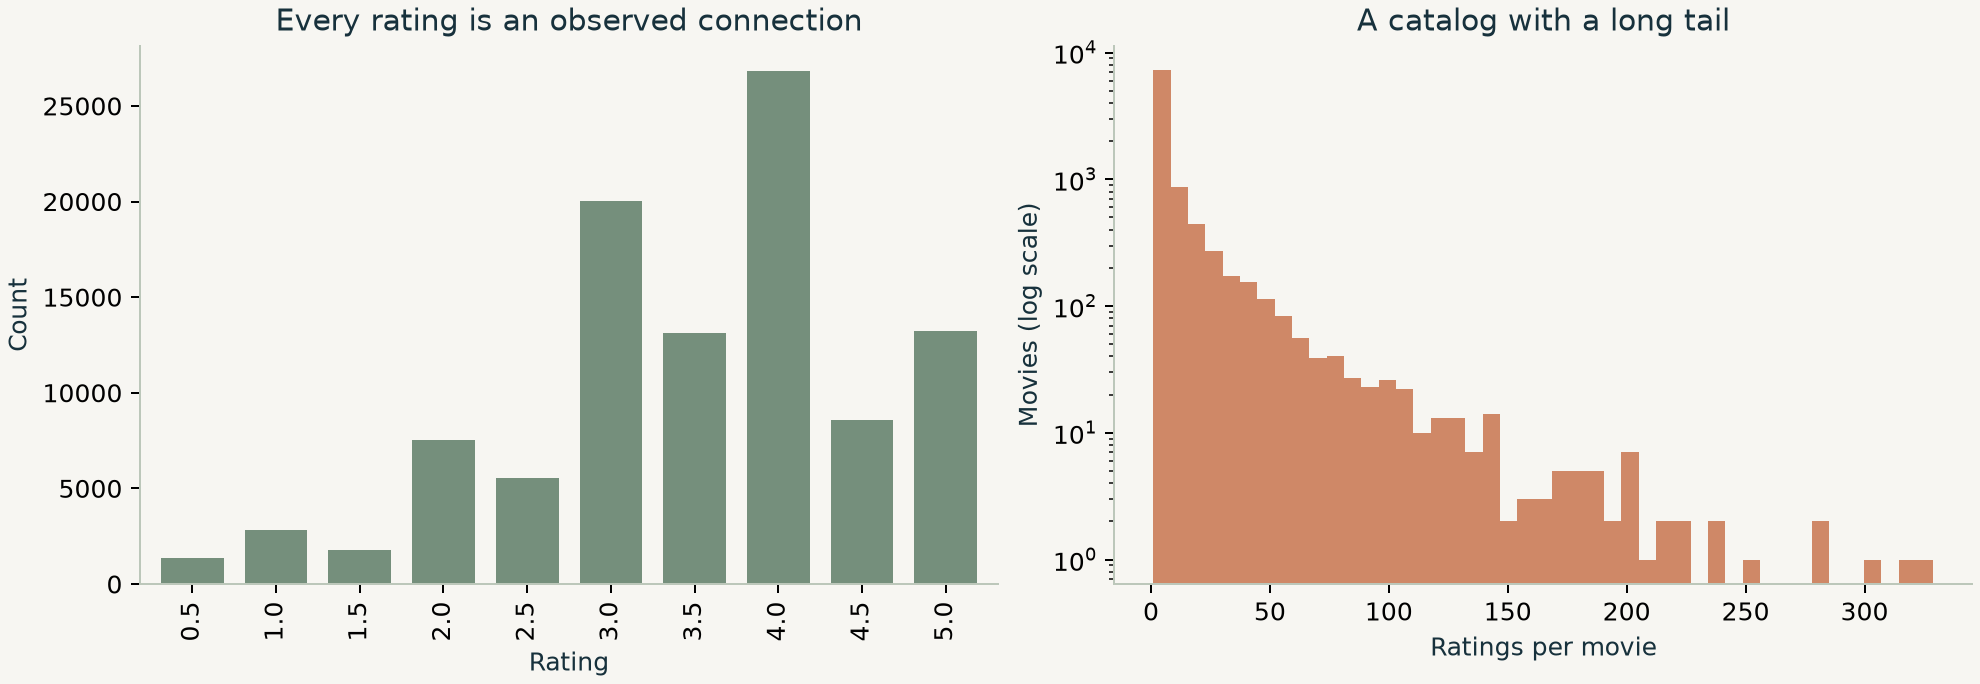

In [4]:
display(Image(filename=str(ROOT/'docs/evidence/data-profile.png')))

## 3 · Similar films, real overlap

In [5]:
similar = client.get('/api/movies/1/similar', params={'limit':5}).json()
[(m['title'],round(m['score'],3),m['support']) for m in similar['items']]

[('Star Wars: Episode IV - A New Hope (1977)', 0.271, 78),
 ('Toy Story 2 (1999)', 0.264, 46),
 ('Sixth Sense, The (1999)', 0.261, 60),
 ('Jurassic Park (1993)', 0.26, 64),
 ('Lion King, The (1994)', 0.256, 57)]

## 4 · Different people, different paths
Every previously rated movie is excluded.

In [6]:
recommendations = {uid:client.get(f'/api/users/{uid}/recommendations',params={'limit':5}).json() for uid in [1,42]}
{uid:[m['title'] for m in response['items']] for uid,response in recommendations.items()}

{1: ['Memento (2000)',
  'Lord of the Rings: The Return of the King, The (2003)',
  'Kill Bill: Vol. 1 (2003)',
  'Departed, The (2006)',
  'Léon: The Professional (a.k.a. The Professional) (Léon) (1994)'],
 42: ['From Russia with Love (1963)',
  'Dr. No (1962)',
  'Man with the Golden Gun, The (1974)',
  'Thunderball (1965)',
  'Spy Who Loved Me, The (1977)']}

## 5 · Explain one recommendation
These are actual rating/similarity paths, not an unconstrained LLM story.

In [7]:
movie_id = recommendations[42]['items'][0]['movie_id']
evidence = client.get(f'/api/users/42/recommendations/{movie_id}/explanation').json()
print(evidence['explanation'])
evidence['evidence']

Supported by movies in your rating history: For Your Eyes Only (1981) (rating 5, similarity 0.276, 9 shared positive raters); Licence to Kill (1989) (rating 5, similarity 0.172, 6 shared positive raters); Cruel Intentions (1999) (rating 5, similarity 0.093, 5 shared positive raters). Evidence shows graph affinity, not certainty.


[{'evidence_id': 'ev-gds-246d37dafdab7423-1',
  'type': 'collaborative_path',
  'path': [{'label': 'User', 'user_id': 42},
   {'relationship': 'RATED', 'score': 5.0},
   {'label': 'Movie', 'movie_id': 2989, 'title': 'For Your Eyes Only (1981)'},
   {'relationship': 'SIMILAR_TO', 'score': 0.2755102040816326},
   {'label': 'Movie', 'movie_id': 2948}],
  'source_rating': 5.0,
  'similarity': 0.2755102040816326,
  'support': 9,
  'contribution': 2.1355413718128187,
  'run_id': 'gds-246d37dafdab7423',
  'provenance': 'derived'},
 {'evidence_id': 'ev-gds-246d37dafdab7423-2',
  'type': 'collaborative_path',
  'path': [{'label': 'User', 'user_id': 42},
   {'relationship': 'RATED', 'score': 5.0},
   {'label': 'Movie', 'movie_id': 2990, 'title': 'Licence to Kill (1989)'},
   {'relationship': 'SIMILAR_TO', 'score': 0.17224880382775118},
   {'label': 'Movie', 'movie_id': 2948}],
  'source_rating': 5.0,
  'similarity': 0.17224880382775118,
  'support': 6,
  'contribution': 1.3351391032705342,
  'ru

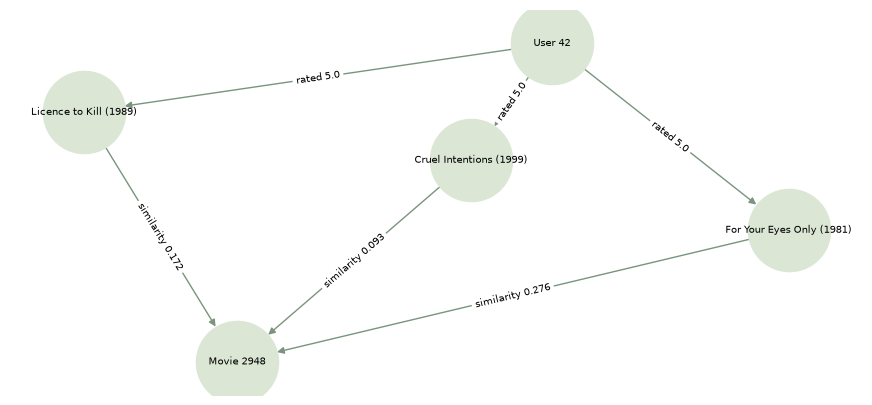

In [8]:
graph = nx.DiGraph()
for ev in evidence['evidence']:
    path = ev['path']
    source = path[2]['title']
    graph.add_edge('User 42', source, label=f"rated {ev['source_rating']}")
    graph.add_edge(source, f'Movie {movie_id}', label=f"similarity {ev['similarity']:.3f}")
fig,ax=plt.subplots(figsize=(11,5))
pos=nx.spring_layout(graph,seed=42)
nx.draw_networkx(graph,pos,ax=ax,node_color='#dce6d5',edge_color='#7a947d',node_size=3500,font_size=7,arrows=True)
nx.draw_networkx_edge_labels(graph,pos,edge_labels=nx.get_edge_attributes(graph,'label'),font_size=7,ax=ax)
ax.axis('off')
plt.show()

## 6 · Community discovery and historical centrality

In [9]:
discovery=client.get('/api/users/42/discover',params={'limit':5}).json()
[(m['title'],round(m['score'],2)) for m in discovery['items']]

[('Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)',
  4.14),
 ('Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)',
  4.14),
 ("One Flew Over the Cuckoo's Nest (1975)", 4.11),
 ('Apocalypse Now (1979)', 4.11),
 ('Monty Python and the Holy Grail (1975)', 4.08)]

In [10]:
gds=json.loads((ROOT/'artifacts/reports/gds.json').read_text())
{k:gds[k] for k in ['gds_version','similarity_edges','communities','duration_seconds','memory_estimate']}

{'gds_version': '2.13.2',
 'similarity_edges': 33679,
 'communities': 7316,
 'duration_seconds': 4.891,
 'memory_estimate': {'requiredMemory': '[8250 KiB ... 8816 KiB]',
  'bytesMin': 8448616,
  'bytesMax': 9028328}}

## 7 · Offline ML, with no future edges in the feature graph
The frozen global-time split produces a difficult cold-start cohort. Read the cohort counts beside aggregate metrics. The model is not a calibrated preference guarantee.

In [11]:
ml=json.loads((ROOT/'artifacts/reports/ml_metrics.json').read_text())
{'block_sizes':ml['block_sizes'],'test':ml['test'],'dummy':ml['dummy_test'],'cold_user_test_count':ml['cold_user_test_count'],'ranking':ml['ranking']}

{'block_sizes': [60501, 20167, 10084, 10084],
 'test': {'n': 8598,
  'positive_rate': 0.4801116538729937,
  'average_precision': 0.6164980042397485,
  'roc_auc': 0.6688907694275359,
  'f1': 0.6773492667028789,
  'confusion_matrix': [[1293, 3177], [387, 3741]]},
 'dummy': {'n': 8598,
  'positive_rate': 0.4801116538729937,
  'average_precision': 0.4801116538729937,
  'roc_auc': 0.5,
  'f1': 0.6487505893446488,
  'confusion_matrix': [[0, 4470], [0, 4128]]},
 'cold_user_test_count': 8379,
 'ranking': {'bayesian_popularity': {'users_evaluated': 72,
   'warm_users': 0,
   'recall_at_10': 0.049979675803819505,
   'ndcg_at_10': 0.2275047882624976,
   'catalog_coverage': 0.003284746458632724,
   'candidate_recall': None},
  'item_cf': {'users_evaluated': 72,
   'warm_users': 4,
   'recall_at_10': 0.05031842919135338,
   'ndcg_at_10': 0.22765725505274645,
   'catalog_coverage': 0.005029768014781359,
   'candidate_recall': 0.04755751845257645}}}

## 8 · Measured performance, not claimed speed
Direct traversal and bounded precomputed candidates may have different rankings; overlap is measured.

In [12]:
benchmark=json.loads((ROOT/'artifacts/reports/benchmark.json').read_text())
{k:benchmark[k] for k in ['direct_graph','precomputed_gds','mean_top10_overlap']}

{'direct_graph': {'samples': 30,
  'p50_ms': 21.786,
  'p95_ms': 42.526,
  'min_ms': 7.956},
 'precomputed_gds': {'samples': 30,
  'p50_ms': 2.614,
  'p95_ms': 4.234,
  'min_ms': 1.715},
 'mean_top10_overlap': 0.9733333333333332}

## 9 · Real local model request and a rejected unsafe request
The key is loaded from the untracked .env and never displayed. If the model server is unavailable, the real error is shown rather than faked.

In [13]:
headers={'X-API-Key':get_settings().app_api_key}
success=client.post('/api/ask',headers=headers,json={'question':'Recommend 5 Sci-Fi movies for user 42','user_id':42,'limit':5})
print('HTTP',success.status_code)
assert success.status_code==200, success.text
if success.status_code==200:
    result=success.json()
    assert result['parameters']['genre']=='Sci-Fi'
    assert all('Sci-Fi' in row['genres'] for row in result['rows'])
    print(result['compiled_cypher'])
    display(result['rows'])
else:
    print(success.json())

HTTP 200
MATCH (u:User {user_id: $user_id})-[r:RATED]->(seed:Movie)
WHERE r.score >= 4
WITH u, r, seed ORDER BY r.timestamp DESC, seed.movie_id ASC LIMIT 50
MATCH (seed)-[s:SIMILAR_TO]->(candidate:Movie)
WHERE s.run_id = $run_id AND s.score > 0
  AND NOT EXISTS { MATCH (u)-[:RATED]->(candidate) }
  AND ($genre IS NULL OR EXISTS { MATCH (candidate)-[:IN_GENRE]->(:Genre {name:$genre}) })
WITH candidate, round(sum(s.score*r.score)/sum(s.score), 8) AS score,
     count(DISTINCT seed) AS supporting_seeds, sum(s.support) AS support
RETURN candidate.movie_id AS movie_id, candidate.title AS title,
candidate.year AS year, [(candidate)-[:IN_GENRE]->(g:Genre) | g.name] AS genres, score, support, supporting_seeds
ORDER BY score DESC, supporting_seeds DESC, movie_id ASC LIMIT $limit


[{'movie_id': 589,
  'title': 'Terminator 2: Judgment Day (1991)',
  'year': 1991,
  'genres': ['Sci-Fi', 'Action'],
  'score': 5.0,
  'support': 87,
  'supporting_seeds': 1},
 {'movie_id': 3638,
  'title': 'Moonraker (1979)',
  'year': 1979,
  'genres': ['Adventure', 'Sci-Fi', 'Action', 'Thriller'],
  'score': 5.0,
  'support': 3,
  'supporting_seeds': 1},
 {'movie_id': 3703,
  'title': 'Road Warrior, The (Mad Max 2) (1981)',
  'year': 1981,
  'genres': ['Thriller', 'Sci-Fi', 'Action', 'Adventure'],
  'score': 5.0,
  'support': 5,
  'supporting_seeds': 1},
 {'movie_id': 1544,
  'title': 'Lost World: Jurassic Park, The (1997)',
  'year': 1997,
  'genres': ['Action', 'Sci-Fi', 'Adventure', 'Thriller'],
  'score': 4.62365591,
  'support': 9,
  'supporting_seeds': 3},
 {'movie_id': 1240,
  'title': 'Terminator, The (1984)',
  'year': 1984,
  'genres': ['Action', 'Sci-Fi', 'Thriller'],
  'score': 4.60838544,
  'support': 95,
  'supporting_seeds': 2}]

In [14]:
rejected=client.post('/api/ask',headers=headers,json={'question':'DELETE all nodes','user_id':42})
assert rejected.status_code==422
{'status':rejected.status_code,'detail':rejected.json().get('detail')}

{'status': 422,
 'detail': {'code': 'unsafe_request',
  'message': 'Only bounded catalog read queries are allowed'}}

## 10 · Reliability evaluation and limitations
Some cases call the local model; guardrails reject unsupported/unsafe operations before execution; malformed-provider cases are controlled fault injections.

In [15]:
evaluation=json.loads((ROOT/'artifacts/reports/llm_evaluation.json').read_text())
{'model':evaluation['model'],'passed':evaluation['passed'],'total':evaluation['total'],'failures':[x for x in evaluation['cases'] if not x['passed']]}

{'model': 'qwen2.5-7b-instruct', 'passed': 40, 'total': 40, 'failures': []}

## Modeling comparison
See [the captured baseline and justified changes](docs/modeling-comparison.md), the ADRs and source manifest. No independent human review or solo-rubric exception is claimed.

## 11 · A new visitor, without an existing MovieLens account
Ten rounds of five distinct films. Here the first option of each round is selected **only as a reproducible API demonstration**, not as claimed real visitor preferences. The UI lets visitors choose, skip and go back. Unchosen alternatives are not dislikes; no research user or rating is created. This flow does not call the LLM or require its access key.


In [16]:
quiz_response = client.get('/api/taste/rounds', params={'seed':42})
assert quiz_response.status_code == 200
quiz = quiz_response.json()['rounds']
assert len(quiz) == 10 and all(len(group) == 5 for group in quiz)
assert len({movie['movie_id'] for group in quiz for movie in group}) == 50
demo_picks = [group[0]['movie_id'] for group in quiz]
personal_response = client.post('/api/taste/recommendations', json={'movie_ids':demo_picks})
assert personal_response.status_code == 200
personal = personal_response.json()
assert personal['items'] and not set(demo_picks) & {movie['movie_id'] for movie in personal['items']}
for movie in personal['items']:
    assert abs(movie['score'] - sum(reason['similarity'] for reason in movie['reasons']) / len(demo_picks)) < 1e-8
[(movie['title'], movie['supporting_seeds']) for movie in personal['items']]


[('Fight Club (1999)', 4),
 ('Eternal Sunshine of the Spotless Mind (2004)', 4),
 ('Memento (2000)', 4),
 ('Shrek (2001)', 4),
 ('Lord of the Rings: The Return of the King, The (2003)', 4),
 ('Sixth Sense, The (1999)', 4),
 ('Kill Bill: Vol. 1 (2003)', 3),
 ('Reservoir Dogs (1992)', 3)]

In [17]:
filtered_response = client.post('/api/taste/recommendations', json={'movie_ids':demo_picks,'genre':'Sci-Fi'})
assert filtered_response.status_code == 200
assert filtered_response.json()['items']
assert all('Sci-Fi' in movie['genres'] for movie in filtered_response.json()['items'])
first_personal = personal['items'][0]
{'recommended':first_personal['title'], 'actual_graph_reasons':first_personal['reasons'][:3],
 'note':personal['note']}


{'recommended': 'Fight Club (1999)',
 'actual_graph_reasons': [{'seed_title': "Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",
   'seed_id': 4973,
   'support': 67,
   'similarity': 0.30119431025228127},
  {'seed_title': 'Donnie Darko (2001)',
   'seed_id': 4878,
   'support': 59,
   'similarity': 0.2760945431472081},
  {'seed_title': 'Léon: The Professional (a.k.a. The Professional) (Léon) (1994)',
   'seed_id': 293,
   'support': 61,
   'similarity': 0.26975496592721476}],
 'note': 'Based on your selections and shared positive MovieLens raters. Unchosen films are not dislikes. Affinity is not a probability or predicted star rating. No visitor account or source rating is stored.'}

In [18]:
client.close()